<a href="https://colab.research.google.com/github/lewinskie254/timeseries-youtube/blob/main/Lecture_5_Timeseries_Analysis_ARMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/bandwidth.csv")

In [3]:
df.head()

,hourly_bandwidth
0,1000.496714
1,1000.969408
2,1002.046019
3,1004.702118
4,1007.447816


<Axes: >

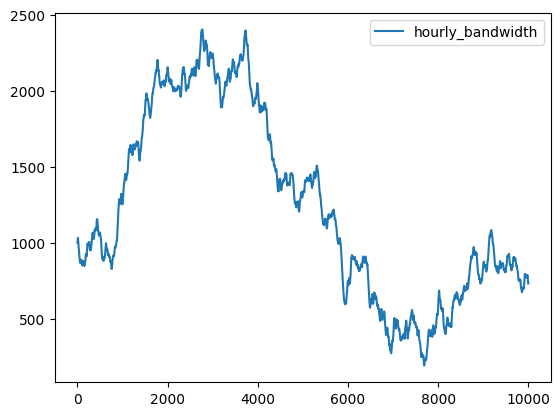

In [4]:
df.plot()

In [5]:
#test for stationarity
results = adfuller(df)
print("ADF Statistic", results[0])
print("P-Value", results[1])

ADF Statistic -0.8714653199452735
P-Value 0.7972240255014551


/tmp/ipykernel_2450/1083296621.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  results = adfuller(df)


In [6]:
df_diff = df.diff()

<Axes: >

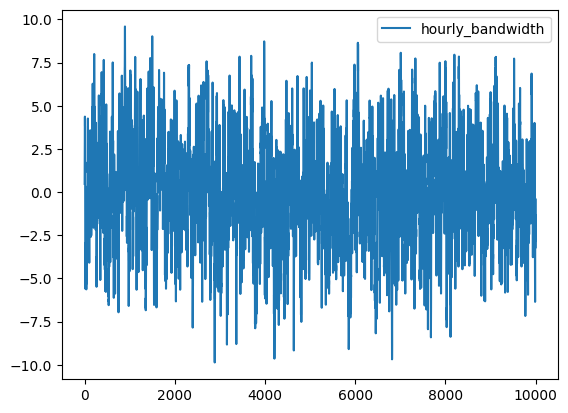

In [7]:
df_diff.plot()

In [8]:
#test for stationarity again

results = adfuller(df_diff[1:])
print("ADF Statistic", results[0])
print("P-Value", results[1])

ADF Statistic -20.694853863789017
P-Value 0.0


/tmp/ipykernel_2450/1938788939.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  results = adfuller(df_diff[1:])


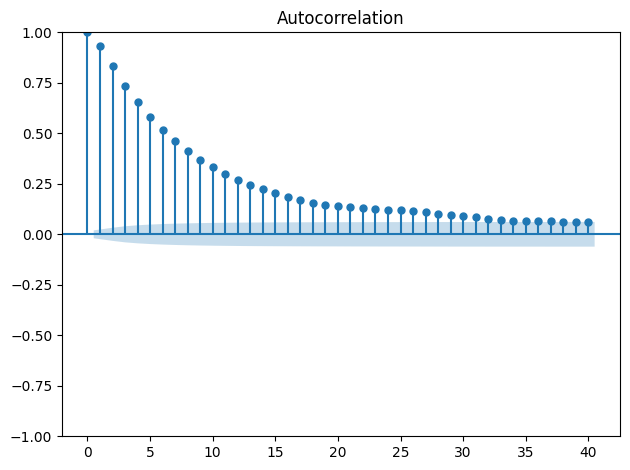

In [9]:
#now that the data is stationary, test if its a moving average process

plot_acf(df_diff[1:])
plt.tight_layout()

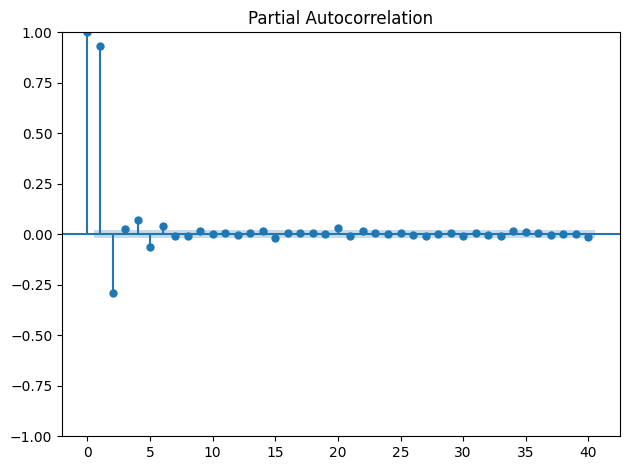

In [10]:
# no abrupt disruption in the trend but rather shows a slow decay, now test to see if its an autoregressive process or not

plot_pacf(df_diff[1:])
plt.tight_layout()

In [11]:
from itertools import product

#set the values of ps as a list of 0 to 5 with a step size of 1
ps = range(0, 5, 1)
#set the values of qs as a list of 0 to 5 with a step size of 1
qs = range(0, 5, 1)

#create a list of all possible combinations of Ps and Qs
order_list = list(product(ps, qs))

In [12]:
print(order_list)

[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]


In [13]:
from typing import Union
from tqdm import tqdm_notebook
from statsmodels.tsa.statespace.sarimax import SARIMAX

# we pass several parameters: the endog (endogenous variables) which can either be a list or a pandas series, and an order list which is a list of tuples.
def optimize_ARMA(endog: Union[pd.Series, list], order_list: list) -> pd.DataFrame:
  #this is a dataframe for storing the model's AIC scores
  results = []
  #we are using tqdm so that we can see the progress in the training as we loop through all combinations
  for order in tqdm_notebook(order_list):
    try:
      #use the sarimax model, indexing into the values of p and q from the orderlist tuples.
      model = SARIMAX(endog, order=(order[0], 0, order[1]), simple_differencing=False).fit(disp=False)
    except:
      #if there is no fit, instead of causing an error, just continue
      continue

    #get the AIC score from the SARIMAX inbuilt AIC property
    aic = model.aic

    #append the results to the results list
    results.append([order, aic])

  #create a dataframe of the rests for easier organization.
  result_df = pd.DataFrame(results)
  #add the column names for the rests
  result_df.columns = ['(p,q)', 'AIC']
  #Sort in ascending order, lower AIC is better
  result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
  return result_df

In [14]:
results_df = optimize_ARMA(df_diff, order_list)

/tmp/ipykernel_2450/1704371442.py:10: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for order in tqdm_notebook(order_list):


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starti

In [15]:
results_df.head(10)

,"(p,q)",AIC
0,"(3, 2)",28451.239020
1,"(2, 3)",28451.415534
2,"(2, 2)",28451.715630
3,"(4, 2)",28452.797770
4,"(2, 4)",28453.233812
5,"(4, 3)",28453.413771
6,"(3, 3)",28453.442374
7,"(1, 4)",28454.142962
8,"(4, 4)",28454.718250
9,"(3, 4)",28455.374598


In [16]:
# So the most optmial values of p and q are (3, 2)
model = SARIMAX(df_diff[1:], order=(3, 0, 2), simple_differencing=False).fit(disp=False)

In [17]:
residuals = model.resid

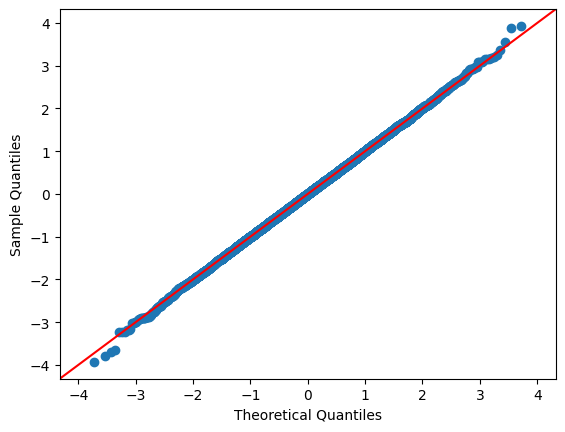

In [18]:
from statsmodels.graphics.gofplots import qqplot
qqplot(residuals, line='45');

In [19]:
from statsmodels.stats.diagnostic import acorr_ljungbox
import numpy as np
acorr_ljungbox(residuals, np.arange(1, 11, 1))

,lb_stat,lb_pvalue
1,0.000648,0.979696
2,0.010038,0.994993
3,0.015823,0.999473
4,0.155965,0.997113
5,0.526432,0.991123
6,0.540256,0.997314
7,0.883341,0.996498
8,1.335704,0.995112
9,1.337165,0.998184
10,1.892958,0.997097


In [32]:
def rolling_forecast(df: pd.DataFrame,train_len: int,horizon: int,window: int,method: str,p: int,q: int) -> list:

    total_len = train_len + horizon

    if method == 'mean':
        pred_mean = []
        for i in tqdm_notebook(range(train_len, total_len, window)):
            mean = np.mean(df[:i].values)
            pred_mean.extend(mean for _ in range(window))
        return pred_mean

    elif method == 'last':
        pred_last_value = []
        for i in tqdm_notebook(range(train_len, total_len, window)):
            last_value = df[:i].iloc[-1].values[0]
            pred_last_value.extend(last_value for _ in range(window))
        return pred_last_value

    elif method == 'ARMA':
        pred_ARMA = []
        for i in tqdm_notebook(range(train_len, total_len, window)):
            model = SARIMAX(df[:i], order=(p, 0, q))
            res = model.fit(disp=False)
            predictions = res.get_prediction(0, i + window - 1)
            oos_pred = predictions.predicted_mean.iloc[-window:]
            pred_ARMA.extend(oos_pred)
        return pred_ARMA

In [30]:
HORIZON = 24*7
TRAIN_LENGTH = len(df_diff) - HORIZON
window = 1
method = 'ARMA'
p = 3
q = 2

In [31]:
preds_LAST = rolling_forecast(df_diff, TRAIN_LENGTH, HORIZON, window, 'last', 0, 0)
pred_ARMA = rolling_forecast(df_diff, TRAIN_LENGTH, HORIZON, window, method, p, q)

/tmp/ipykernel_2450/2755092214.py:22: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for i in tqdm_notebook(range(train_len, total_len, window)):


  0%|          | 0/168 [00:00<?, ?it/s]

/tmp/ipykernel_2450/2755092214.py:15: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for i in tqdm_notebook(range(train_len, total_len, window)):


  0%|          | 0/168 [00:00<?, ?it/s]

/tmp/ipykernel_2450/2755092214.py:29: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for i in tqdm_notebook(range(train_len, total_len, window)):


  0%|          | 0/168 [00:00<?, ?it/s]

In [45]:
test = pd.DataFrame()
test['actual'] = df_diff[TRAIN_LENGTH:]
test['last'] = preds_LAST
test['ARMA'] = pred_ARMA

In [47]:
test

,actual,last,ARMA
9832,-5.943995,-5.791207,-5.453470
9833,-5.865194,-5.943995,-5.477567
9834,-3.197066,-5.865194,-5.347632
9835,-1.090197,-3.197066,-2.164184
9836,0.665291,-1.090197,-0.407950
...,...,...,...
9995,-0.387182,-2.085946,-1.660119
9996,-1.639832,-0.387182,0.310862
9997,-2.848232,-1.639832,-2.114596
9998,-2.498356,-2.848232,-2.975087


In [48]:
df['preds_ARMA'] = df.iloc[TRAIN_LENGTH] + test['ARMA'].cumsum()

In [50]:
df.tail()

,hourly_bandwidth,preds_ARMA
9995,740.546059,NaN
9996,738.906228,NaN
9997,736.057995,NaN
9998,733.559640,NaN
9999,732.190049,NaN
